`Выполнил: Кожеватов Алексей Дмитриевич | Группа: 3825М1сФИ1 | Тема: Метод обратного распространения ошибки`

# Лабораторная работа № 1
## Метод обратного распространения ошибки

**Цель моей работы** — изучить метод обратного распространения ошибки на примере двухслойной полносвязной нейросети с одним скрытым слоем и обучить её классифицировать цифры из набора MNIST.

Вычисления я реализовал на NumPy, без TensorFlow, Keras и PyTorch. В ноутбуке я последовательно загружаю данные, проверяю изображения, выполняю предобработку, записываю формулы градиентов, обучаю сеть и оцениваю её на тестовой выборке.


## 1. Импорты и параметры

Для вычислений я использую NumPy, для визуализации — Matplotlib. При первом запуске я скачиваю архивы MNIST и сохраняю их в папке `data/mnist` рядом с ноутбуком, внутри папки `KozhevatovAD`.

В качестве контрольных параметров я задаю скрытый слой из 300 нейронов, скорость обучения 0.1, размер мини-пачки 64 и 20 эпох.

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Ищу папку с ноутбуком, чтобы кэш MNIST лежал рядом с ним.
current_dir = Path.cwd().resolve()
if current_dir.name == "KozhevatovAD":
    NOTEBOOK_DIR = current_dir
elif (current_dir / "laboratory_work_1" / "KozhevatovAD" / "laboratory_work_1.ipynb").exists():
    NOTEBOOK_DIR = current_dir / "laboratory_work_1" / "KozhevatovAD"
else:
    raise FileNotFoundError("Запустите ноутбук из папки KozhevatovAD или из корня репозитория")
DATA_DIR = NOTEBOOK_DIR / "data" / "mnist"
MNIST_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz",
]

INPUT_SIZE = 28 * 28
HIDDEN_SIZE = 300
OUTPUT_SIZE = 10
BATCH_SIZE = 64
LEARNING_RATE = 0.1
EPOCHS = 20
SEED = 67

print("Параметры:")
print(f"  сеть: {INPUT_SIZE} -> {HIDDEN_SIZE} -> {OUTPUT_SIZE}")
print(f"  размер мини-пачки: {BATCH_SIZE}; скорость обучения: {LEARNING_RATE}; эпох: {EPOCHS}")
print(f"  папка данных: {DATA_DIR}")

Параметры:
  сеть: 784 -> 300 -> 10
  размер мини-пачки: 64; скорость обучения: 0.1; эпох: 20
  папка данных: C:\Users\tryme\OneDrive\Рабочий стол\deep-learning-course-practice-2026\laboratory_work_1\KozhevatovAD\data\mnist


## 2. Загрузка и чтение MNIST

Набор MNIST состоит из четырёх IDX-файлов: обучающих изображений и меток, а также тестовых изображений и меток. Файлы сжаты gzip. В заголовке IDX записаны код формата и число объектов; для файла изображений там также указаны высота и ширина.

Я скачиваю каждый файл только в том случае, если его ещё нет в кэше. Проверяя код формата `magic`, я убеждаюсь, что читаю ожидаемый тип IDX-файла.

In [2]:
def get_mnist_file(filename):
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Скачиваю {filename}...")
        urllib.request.urlretrieve(MNIST_URL + filename, path)
    return path


def read_images(path):
    with gzip.open(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"Неожиданный формат файла изображений: {path}")
        return np.frombuffer(file.read(), dtype=np.uint8).reshape(count, rows, cols)


def read_labels(path):
    with gzip.open(path, "rb") as file:
        magic, count = struct.unpack(">II", file.read(8))
        if magic != 2049:
            raise ValueError(f"Неожиданный формат файла меток: {path}")
        labels = np.frombuffer(file.read(), dtype=np.uint8).copy()
        if len(labels) != count:
            raise ValueError("Число меток не совпало с заголовком IDX")
        return labels


def load_mnist():
    paths = [get_mnist_file(name) for name in FILES]
    x_train = read_images(paths[0])
    y_train = read_labels(paths[1])
    x_test = read_images(paths[2])
    y_test = read_labels(paths[3])
    return x_train, y_train, x_test, y_test

## 3. Загрузка и проверка размерностей

`X` — изображения, `y` — правильные ответы-метки. Для полного MNIST я ожидаю 60 000 обучающих и 10 000 тестовых изображений. Каждое изображение — матрица `28 × 28`, а каждая метка — одно целое число от 0 до 9.

In [3]:
x_train_images, y_train, x_test_images, y_test = load_mnist()

print("Размерности данных:")
print(f"  обучающая выборка: X={x_train_images.shape}, y={y_train.shape}")
print(f"  тестовая выборка:  X={x_test_images.shape}, y={y_test.shape}")
print(f"  форма одного изображения: {x_train_images[0].shape}")
print(f"  форма одной метки: {y_train[0].shape} (скаляр)")
print(f"  первые 10 меток обучающей выборки: {y_train[:10].tolist()}")

Размерности данных:
  обучающая выборка: X=(60000, 28, 28), y=(60000,)
  тестовая выборка:  X=(10000, 28, 28), y=(10000,)
  форма одного изображения: (28, 28)
  форма одной метки: () (скаляр)
  первые 10 меток обучающей выборки: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4]


## 4. Примеры изображений с метками

Я вывожу десять изображений из обучающей выборки. Подпись над каждым изображением показывает метку из файла MNIST. Так я визуально проверяю, что изображения и соответствующие им метки загружены правильно.

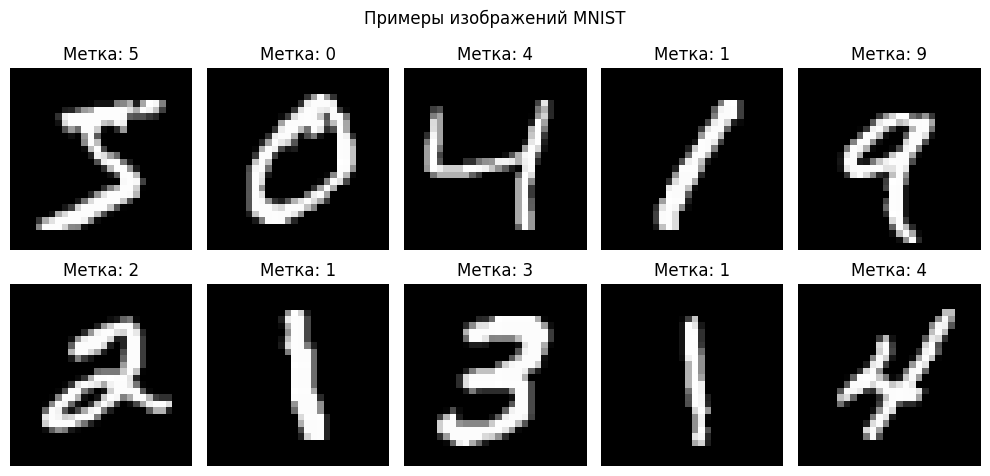

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train_images[i], cmap="gray")
    ax.set_title(f"Метка: {int(y_train[i])}")
    ax.axis("off")
fig.suptitle("Примеры изображений MNIST")
fig.tight_layout()
plt.show()

## 5. Предобработка

Сначала я разворачиваю каждое изображение `28 × 28` в строку длины 784, потому что сеть принимает вектор признаков. Затем перевожу значения пикселей из `uint8` и диапазона `[0, 255]` в `float32` и нормализую их к `[0, 1]`, деля на 255. Метки я оставляю целыми числами от 0 до 9: отдельное унитарное кодирование здесь не требуется, так как в градиенте я корректирую координату правильного класса напрямую.

In [5]:
x_train = x_train_images.reshape(len(x_train_images), INPUT_SIZE).astype(np.float32) / 255.0
x_test = x_test_images.reshape(len(x_test_images), INPUT_SIZE).astype(np.float32) / 255.0

print("После предобработки:")
print(f"  обучающие изображения: {x_train.shape}, тип: {x_train.dtype}, диапазон: [{x_train.min():.1f}, {x_train.max():.1f}]")
print(f"  тестовые изображения:  {x_test.shape}, тип: {x_test.dtype}, диапазон: [{x_test.min():.1f}, {x_test.max():.1f}]")
print(f"  метки обучающей выборки: {y_train.shape}, классы: {np.unique(y_train).tolist()}")

После предобработки:
  обучающие изображения: (60000, 784), тип: float32, диапазон: [0.0, 1.0]
  тестовые изображения:  (10000, 784), тип: float32, диапазон: [0.0, 1.0]
  метки обучающей выборки: (60000,), классы: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 6. Архитектура сети и вывод градиентов

Для одного мини-пакета обозначу входные изображения через $X$, правильные ответы в унитарном виде — через $Y$, матрицы весов — через $W_1$ и $W_2$, а смещения — через $b_1$ и $b_2$. Размер мини-пакета обозначу $B$.

### 6.1. Прямой проход

Сначала вычисляю значения на скрытом слое и применяю ReLU:

$$
Z_1 = XW_1 + b_1
$$

$$
A_1 = \operatorname{ReLU}(Z_1) = \max(0, Z_1)
$$

Затем вычисляю выходные оценки классов и преобразую их в вероятности с помощью softmax:

$$
Z_2 = A_1W_2 + b_2
$$

$$
p_{ij} = \frac{e^{z_{ij}}}{\sum_{k=1}^{10} e^{z_{ik}}}
$$

Здесь $p_{ij}$ — вероятность того, что изображение $i$ относится к классу $j$. Для каждого изображения сумма десяти вероятностей равна единице.

### 6.2. Функция ошибки

Для одного изображения кросс-энтропия равна:

$$
\ell = -\sum_{j=1}^{10} y_j \log(p_j)
$$

Для мини-пакета я усредняю ошибку по всем $B$ изображениям:

$$
L = \frac{1}{B}\sum_{i=1}^{B} \ell_i
$$

Вектор $Y$ содержит единицу у правильного класса и нули у остальных. В коде я не создаю этот вектор явно: вместо этого вычитаю единицу из вероятности правильного класса.

### 6.3. Градиент на выходном слое

Пусть $z_{2,k}$ — выходная оценка класса $k$. Производная кросс-энтропии с softmax по этой оценке упрощается до разности между предсказанной вероятностью и правильным ответом:

$$
\frac{\partial \ell}{\partial z_{2,k}} = p_k - y_k
$$

Для среднего значения ошибки на мини-пакете делю градиент на размер пакета:

$$
\delta_2 = \frac{P-Y}{B}
$$

Отсюда получаю градиенты выходных весов и смещений:

$$
\nabla W_2 = A_1^T\delta_2
$$

$$
\nabla b_2 = \sum_{i=1}^{B}\delta_{2,i}
$$

### 6.4. Передача ошибки к скрытому слою

Производная ReLU равна единице для положительных входов и нулю для неположительных:

$$
\operatorname{ReLU}'(z) =
\begin{cases}
1, & z > 0 \\
0, & z \leq 0
\end{cases}
$$

По правилу цепочки передаю градиент назад через матрицу $W_2$ и учитываю производную ReLU:

$$
\delta_1 = (\delta_2 W_2^T) \odot \mathbf{1}[Z_1 > 0]
$$

Знак $\odot$ означает поэлементное умножение. Теперь вычисляю градиенты первого слоя:

$$
\nabla W_1 = X^T\delta_1
$$

$$
\nabla b_1 = \sum_{i=1}^{B}\delta_{1,i}
$$

### 6.5. Коррекция параметров

Метод стохастического градиентного спуска изменяет каждый параметр в направлении, противоположном градиенту ошибки:

$$
W_1 \leftarrow W_1 - \eta\nabla W_1, \qquad b_1 \leftarrow b_1 - \eta\nabla b_1
$$

$$
W_2 \leftarrow W_2 - \eta\nabla W_2, \qquad b_2 \leftarrow b_2 - \eta\nabla b_2
$$

Здесь $\eta$ — скорость обучения (`LEARNING_RATE`). В коде эти обновления выполняются после вычисления всех градиентов текущего мини-пакета.

## 7. Инициализация параметров

Я задаю весам разные случайные начальные значения: иначе нейроны одного слоя получали бы одинаковые градиенты и обучались одинаково. Для скрытого слоя с ReLU я использую инициализацию Хе. Смещения начинаю с нуля.

In [6]:
rng = np.random.default_rng(SEED)

w1 = (rng.standard_normal((INPUT_SIZE, HIDDEN_SIZE)) * np.sqrt(2.0 / INPUT_SIZE)).astype(np.float32)
b1 = np.zeros(HIDDEN_SIZE, dtype=np.float32)
w2 = (rng.standard_normal((HIDDEN_SIZE, OUTPUT_SIZE)) * np.sqrt(1.0 / HIDDEN_SIZE)).astype(np.float32)
b2 = np.zeros(OUTPUT_SIZE, dtype=np.float32)

print("Формы параметров:")
print(f"  W1={w1.shape}, b1={b1.shape}")
print(f"  W2={w2.shape}, b2={b2.shape}")
print(f"  среднее W1={w1.mean():.5f}, стандартное отклонение W1={w1.std():.5f}")

Формы параметров:
  W1=(784, 300), b1=(300,)
  W2=(300, 10), b2=(10,)
  среднее W1=-0.00004, стандартное отклонение W1=0.05050


## 8. Функции прямого прохода и оценки качества

Функция `softmax` преобразует десять выходных оценок в вероятности, сумма которых равна единице. Перед вычислением экспоненты я вычитаю максимальное значение строки: это не меняет результат softmax, но делает вычисления устойчивее.

Функцией `evaluate` я вычисляю среднюю кросс-энтропию и долю правильных ответов. Ошибку классификации я считаю как `1 − точность`.

In [7]:
def softmax(logits):
    logits = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(logits)
    return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)


def predict_proba(x, w1, b1, w2, b2):
    hidden = np.maximum(x @ w1 + b1, 0.0)  # ReLU
    return softmax(hidden @ w2 + b2)


def evaluate(x, y, w1, b1, w2, b2):
    probabilities = predict_proba(x, w1, b1, w2, b2)
    correct = np.argmax(probabilities, axis=1) == y
    true_class_probabilities = probabilities[np.arange(len(y)), y]
    loss = -np.mean(np.log(np.clip(true_class_probabilities, 1e-12, 1.0)))
    accuracy = np.mean(correct)
    return loss, accuracy

print("Функции softmax, predict_proba и evaluate определены.")

Функции softmax, predict_proba и evaluate определены.


## 9. Одна эпоха обучения: стохастический градиентный спуск по мини-пачкам и обратное распространение ошибки

В начале каждой эпохи я перемешиваю примеры. Затем для каждой мини-пачки выполняю прямой проход, вычисляю градиенты и обновляю веса. Копируя вероятности в `delta2`, я не изменяю исходный массив вероятностей при вычислении градиента.

In [8]:
def train_epoch(x, y, w1, b1, w2, b2, rng):
    order = rng.permutation(len(x))

    for start in range(0, len(x), BATCH_SIZE):
        indices = order[start:start + BATCH_SIZE]
        xb = x[indices]
        yb = y[indices]
        batch_size = len(xb)

        # Прямой проход
        z1 = xb @ w1 + b1
        a1 = np.maximum(z1, 0.0)
        probabilities = softmax(a1 @ w2 + b2)

        # dL/dZ2 = (P - Y) / batch_size.
        delta2 = probabilities.copy()
        delta2[np.arange(batch_size), yb] -= 1.0
        delta2 /= batch_size

        # Градиенты выходного слоя
        grad_w2 = a1.T @ delta2
        grad_b2 = np.sum(delta2, axis=0)

        # Передача ошибки к скрытому слою через веса и производную ReLU
        delta1 = (delta2 @ w2.T) * (z1 > 0.0)

        # Градиенты скрытого слоя
        grad_w1 = xb.T @ delta1
        grad_b1 = np.sum(delta1, axis=0)

        # Шаг стохастического градиентного спуска
        w1 -= LEARNING_RATE * grad_w1
        b1 -= LEARNING_RATE * grad_b1
        w2 -= LEARNING_RATE * grad_w2
        b2 -= LEARNING_RATE * grad_b2

print("Функция train_epoch определена.")

Функция train_epoch определена.


## 10. Обучение

После каждой эпохи я измеряю ошибку классификации и время выполнения. Метрики на обучающей выборке я считаю после обновления весов в этой эпохе. Ошибка классификации показывает долю неверных ответов; дополнительно я вывожу значение кросс-энтропии.

In [9]:
print("Начинаю обучение")
print(f"скрытых нейронов={HIDDEN_SIZE}, размер мини-пачки={BATCH_SIZE}, скорость обучения={LEARNING_RATE}, эпох={EPOCHS}")

for epoch in range(1, EPOCHS + 1):
    start_time = time.perf_counter()

    train_epoch(x_train, y_train, w1, b1, w2, b2, rng)
    train_loss, train_accuracy = evaluate(x_train, y_train, w1, b1, w2, b2)

    epoch_seconds = time.perf_counter() - start_time
    train_error = 1.0 - train_accuracy
    print(
        f"Эпоха {epoch:02d}/{EPOCHS}: "
        f"кросс-энтропия={train_loss:.4f}, "
        f"ошибка классификации={train_error:.2%}, точность={train_accuracy:.2%}, "
        f"время={epoch_seconds:.2f} с"
    )

Начинаю обучение
скрытых нейронов=300, размер мини-пачки=64, скорость обучения=0.1, эпох=20
Эпоха 01/20: кросс-энтропия=0.2359, ошибка классификации=6.53%, точность=93.47%, время=0.88 с
Эпоха 02/20: кросс-энтропия=0.1704, ошибка классификации=4.95%, точность=95.05%, время=0.74 с
Эпоха 03/20: кросс-энтропия=0.1229, ошибка классификации=3.36%, точность=96.64%, время=0.81 с
Эпоха 04/20: кросс-энтропия=0.1019, ошибка классификации=2.85%, точность=97.15%, время=0.72 с
Эпоха 05/20: кросс-энтропия=0.0814, ошибка классификации=2.16%, точность=97.84%, время=0.76 с
Эпоха 06/20: кросс-энтропия=0.0744, ошибка классификации=2.10%, точность=97.90%, время=0.78 с
Эпоха 07/20: кросс-энтропия=0.0654, ошибка классификации=1.81%, точность=98.19%, время=0.76 с
Эпоха 08/20: кросс-энтропия=0.0557, ошибка классификации=1.49%, точность=98.52%, время=0.77 с
Эпоха 09/20: кросс-энтропия=0.0494, ошибка классификации=1.31%, точность=98.69%, время=0.84 с
Эпоха 10/20: кросс-энтропия=0.0477, ошибка классификации=1.32%

## 11. Итоговая оценка на тестовой выборке

При обновлении весов я не использовал тестовую выборку. После обучения я проверяю на ней, насколько хорошо модель распознаёт примеры, которые не участвовали в обучении. Эту оценку я использую как основной итоговый показатель качества.

In [10]:
test_loss, test_accuracy = evaluate(x_test, y_test, w1, b1, w2, b2)
test_error = 1.0 - test_accuracy

print("Результат на тестовой выборке:")
print(f"  кросс-энтропия: {test_loss:.4f}")
print(f"  точность:       {test_accuracy:.2%}")
print(f"  ошибка:        {test_error:.2%}")

Результат на тестовой выборке:
  кросс-энтропия: 0.0634
  точность:       98.09%
  ошибка:        1.91%


## 12. Примеры предсказаний модели

Дополнительно приведу несколько тестовых изображений. Над каждым изображением я указываю правильный класс и предсказание сети. Это наглядная проверка результатов на отдельных примерах.

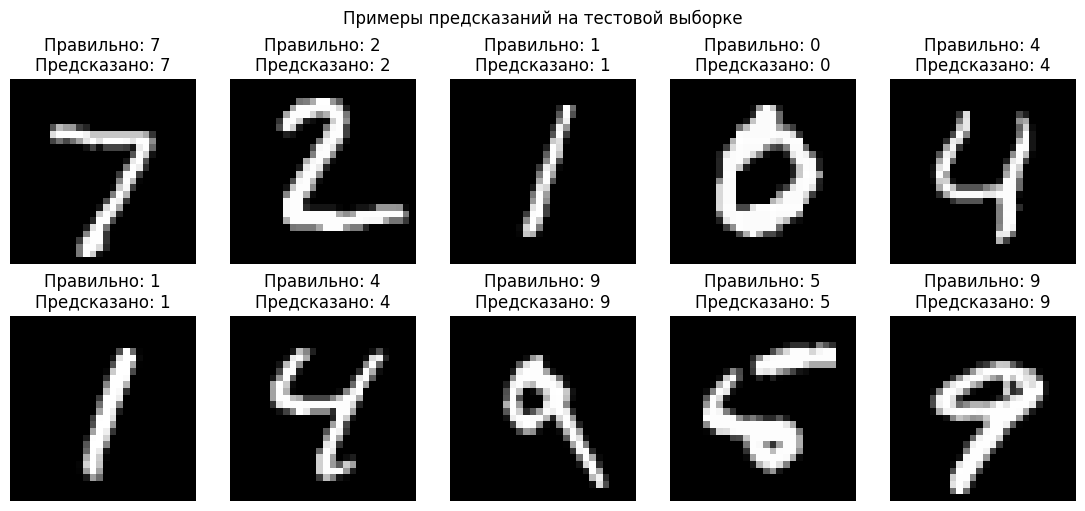

In [11]:
count = 10
probabilities = predict_proba(x_test[:count], w1, b1, w2, b2)
predictions = np.argmax(probabilities, axis=1)

# Добавляем constrained_layout=True
fig, axes = plt.subplots(2, 5, figsize=(11, 5), constrained_layout=True)

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test_images[i], cmap="gray")
    ax.set_title(f"Правильно: {int(y_test[i])}\nПредсказано: {int(predictions[i])}")
    ax.axis("off")

fig.suptitle("Примеры предсказаний на тестовой выборке")
# fig.tight_layout()  <-- Эту строку нужно УДАЛИТЬ или закомментировать
plt.show()

## Вывод

В работе я реализовал двухслойную полносвязную нейронную сеть для классификации MNIST. Я обучал её методом стохастического градиентного спуска по мини-пачкам, а градиенты вычислял методом обратного распространения ошибки.